# EDA: OpenSSH

Исследование по 11 пунктам чеклиста. Данные приходят через Python-функцию из `util/loghub_systems.py`; вычисления вынесены в `util/loghub_eda.py`. Запуск: установить `requirements-eda-systems.txt`, выбрать это Python-окружение и выполнить **Restart Kernel → Run All**. Порядок ячеек самодостаточен.

Область анализа явно отмечена: полный поток и случайная выборка не смешиваются. Числа в таблицах вычисляются из данных, пропуски и ограничения сохраняются.

## 1. Происхождение данных

Логи сервера OpenSSH в лаборатории авторов LogHub, собранные за 28+ дней. Каталог указывает 655 146 строк и 70,02 MiB. Используем весь `SSH.log` из архива `SSH.tar.gz`, а не демонстрационный файл `_2k`. Разметки аномалий нет. Год, часовой пояс, подробности нагрузки и предшествующей фильтрации не опубликованы.

**Ось времени условная:** в исходном syslog есть месяц, день и часы, но нет года. Выбираем 2000 как техническую точку отсчёта; переход Dec → Jan увеличивает год до 2001. Это не установленные годы сбора. Дни недели и календарную сезонность по такой оси не интерпретируем.

Источники: [описание OpenSSH](https://github.com/logpai/loghub/tree/master/OpenSSH), [каталог LogHub](https://github.com/logpai/loghub), [неизменяемая версия архива Zenodo 8196385](https://zenodo.org/records/8196385). Размер и MD5 закреплены в загрузчике по метаданным Zenodo. LogHub разрешает исследовательское/академическое использование; при распространении нужно ссылаться на LogHub и статью. Заявление LogHub «по возможности без изменений» не является гарантией отсутствия фильтрации конкретного источника.

In [1]:
import sys
import platform
from pathlib import Path
from importlib.metadata import version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, JSON

PROJECT_ROOT = next(
    p for p in (Path.cwd(), *Path.cwd().parents)
    if (p / "util" / "loghub_systems.py").exists()
)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from util.loghub_systems import load_small, load_thunderbird, SOURCES
from util.loghub_eda import (
    reconstruct_events, quality_table, minute_counts, dense_minutes,
    time_summary, largest_gaps, zero_runs, distribution, drift,
    message_statistics, entity_counts, component_mentions,
    session_candidates, mine_templates, window_summary, alert_episodes,
)

SEED = 42
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.figsize": (12, 4), "figure.dpi": 110})
pd.set_option("display.max_columns", 12)
pd.set_option("display.max_colwidth", 140)
environment = {package: version(package) for package in ["numpy", "pandas", "matplotlib", "drain3", "nbclient"]}
display({"python": platform.python_version(), "executable": sys.executable, **environment})

{'python': '3.12.6',
 'executable': 'C:\\Users\\Georges\\Documents\\HSE\\year_project\\hse-ai-2026-cloud-anomaly-detection\\.venv\\Scripts\\python.exe',
 'numpy': '2.3.5',
 'pandas': '2.3.3',
 'matplotlib': '3.10.6',
 'drain3': '0.9.11',
 'nbclient': '0.10.2'}

In [2]:
NAME = "OpenSSH"
physical, source = load_small(NAME)
prefix = physical
events_all = reconstruct_events(physical)
events = events_all.loc[events_all.parse_ok].copy()
minutes = minute_counts(events)
SCOPE = "все физические строки и восстановленные события полного файла"
assert len(physical) == source["physical_lines"]
assert events_all.physical_line_count.sum() == len(physical)
assert minutes["count"].sum() == events.timestamp.notna().sum()
dense = dense_minutes(minutes)
display({"analysis_scope": SCOPE, "source": source["url"], "MD5 archive": source["archive_md5"], "SHA256 raw": source["sha256_raw"]})

{'analysis_scope': 'все физические строки и восстановленные события полного файла',
 'source': 'https://zenodo.org/records/8196385/files/SSH.tar.gz?download=1',
 'MD5 archive': 'a44e40b4348697dabf2bba56885e0a38',
 'SHA256 raw': '89eee9e36c182722f9fadc6e5617a4818ffc66109e7e222b8f9e8b78fc3aa2f3'}

## 2. Физическая организация

Архив tar.gz содержит текстовый `.log`. Читаем бинарные строки по LF, отдельно считаем CRLF, проверяем строгое декодирование UTF-8. При ошибке сохраняем строку с replacement-символом и учитываем ошибку; строки не исчезают молча. Отсутствие финального LF само по себе не доказывает обрыв. Наличие даты и PID зависит от источника.

ZooKeeper: `YYYY-MM-DD HH:MM:SS,mmm - LEVEL [context:Class@line] - message`. OpenSSH/Mac: `Mon day HH:MM:SS host process[pid]: message`, при этом Mac допускает пробелы в имени процесса и строки продолжения.

In [3]:
display(pd.Series({key: source.get(key, 0) for key in ["member", "member_bytes", "physical_lines", "bytes", "crlf", "lf", "no_final_lf", "invalid_utf8_lines"]}, name="source_fact"))
display(physical.dtypes.astype(str).to_frame("parsed_dtype"))

member                 SSH.log
member_bytes          73417506
physical_lines          655147
bytes                 73417506
crlf                    655146
lf                           0
no_final_lf                  1
invalid_utf8_lines           0
Name: source_fact, dtype: object

,parsed_dtype
line_no,int64
raw,object
parse_ok,bool
header_start,bool
message,object
host,object
component,object
level,object
pid,object
label,object


## 3. Первичный осмотр и качество

Ниже — **100 первых и 100 случайных строк целиком**, с номерами в исходном файле. Случайный отбор детерминирован. Дубли считаем по полному тексту, включая заголовок; это наблюдение, а не команда удалить записи. Выбросы и ошибки парсинга показываем отдельно.

В таблице различаются физические строки и события. Наличие многострочных событий проверяется после восстановления; это эвристика по границам заголовков.

In [4]:
with pd.option_context("display.max_rows", 100, "display.max_colwidth", None):
    display(prefix[["line_no", "raw"]].head(100))
    display(physical[["line_no", "raw"]].sample(n=min(100, len(physical)), random_state=SEED).sort_values("line_no"))

,line_no,raw
0,1,Dec 10 06:55:46 LabSZ sshd[24200]: reverse mapping checking getaddrinfo for ns.marryaldkfaczcz.com [173.234.31.186] failed - POSSIBLE BREAK-IN ATTEMPT!
1,2,Dec 10 06:55:46 LabSZ sshd[24200]: Invalid user webmaster from 173.234.31.186
2,3,Dec 10 06:55:46 LabSZ sshd[24200]: input_userauth_request: invalid user webmaster [preauth]
3,4,Dec 10 06:55:46 LabSZ sshd[24200]: pam_unix(sshd:auth): check pass; user unknown
4,5,Dec 10 06:55:46 LabSZ sshd[24200]: pam_unix(sshd:auth): authentication failure; logname= uid=0 euid=0 tty=ssh ruser= rhost=173.234.31.186
5,6,Dec 10 06:55:48 LabSZ sshd[24200]: Failed password for invalid user webmaster from 173.234.31.186 port 38926 ssh2
6,7,Dec 10 06:55:48 LabSZ sshd[24200]: Connection closed by 173.234.31.186 [preauth]
7,8,Dec 10 07:02:47 LabSZ sshd[24203]: Connection closed by 212.47.254.145 [preauth]
8,9,Dec 10 07:07:38 LabSZ sshd[24206]: Invalid user test9 from 52.80.34.196
9,10,Dec 10 07:07:38 LabSZ sshd[24206]: input_userauth_request: invalid user test9 [preauth]


,line_no,raw
1496,1497,Dec 10 10:59:41 LabSZ sshd[25203]: pam_unix(sshd:auth): authentication failure; logname= uid=0 euid=0 tty=ssh ruser= rhost=183.62.140.253 user=root
1551,1552,Dec 10 11:00:18 LabSZ sshd[25242]: Failed password for root from 183.62.140.253 port 43414 ssh2
10865,10866,Dec 10 12:29:53 LabSZ sshd[31197]: Received disconnect from 183.62.140.253: 11: Bye Bye [preauth]
17062,17063,Dec 10 13:30:30 LabSZ sshd[3312]: Failed password for root from 183.62.140.253 port 34025 ssh2
25466,25467,Dec 10 14:52:02 LabSZ sshd[9498]: pam_unix(sshd:auth): authentication failure; logname= uid=0 euid=0 tty=ssh ruser= rhost=183.62.140.253 user=root
31915,31916,Dec 10 16:02:56 LabSZ sshd[14195]: pam_unix(sshd:auth): authentication failure; logname= uid=0 euid=0 tty=ssh ruser= rhost=183.62.140.253 user=root
33983,33984,Dec 10 16:26:52 LabSZ sshd[15801]: pam_unix(sshd:auth): authentication failure; logname= uid=0 euid=0 tty=ssh ruser= rhost=183.62.140.253 user=root
37660,37661,Dec 10 17:09:42 LabSZ sshd[18513]: Failed password for root from 183.62.140.253 port 36456 ssh2
39390,39391,Dec 11 00:11:30 LabSZ sshd[20133]: pam_unix(sshd:auth): authentication failure; logname= uid=0 euid=0 tty=ssh ruser= rhost=58.42.244.194
53180,53181,Dec 11 19:10:10 LabSZ sshd[29424]: pam_unix(sshd:auth): authentication failure; logname= uid=0 euid=0 tty=ssh ruser= rhost=183.63.172.52 user=root


In [5]:
quality = quality_table(physical, source, events_all)
display(quality.to_frame())
display(physical.loc[~physical.parse_ok, ["line_no", "raw"]].head(15))
display(events.loc[events.physical_line_count.gt(1), ["line_no", "physical_line_count", "message"]].head(5))
display(physical.loc[physical.raw.duplicated(keep=False), ["line_no", "raw"]].head(10))

,value
source_physical_lines (full),6.551470e+05
published_lines (reference),6.551460e+05
source_bytes (full),7.341751e+07
analyzed_physical_lines,6.551470e+05
analyzed_events,6.551470e+05
mean_line_characters,1.100626e+02
blank_lines,0.000000e+00
duplicate_raw_lines_beyond_first,0.000000e+00
unparsed_physical_lines,0.000000e+00
without_header_start,0.000000e+00


,line_no,raw


,line_no,physical_line_count,message


,line_no,raw


## 4. Время

Порядок в файле и хронологический порядок проверяются отдельно. Повторяющиеся timestamps допустимы для одновременных событий. Пустые интервалы означают отсутствие записей в опубликованном файле; без метрик доступности нельзя отличить простой системы от потери логов.

В ZooKeeper разрешение 1 ms; OpenSSH и Mac — 1 s. Часовой пояс не указан, поэтому timestamps остаются timezone-naive. Для syslog годы синтетические, переход года учитывается. Мы не утверждаем, что все машины использовали один пояс.

In [6]:
display(time_summary(events).to_frame("analyzed_events"))
display(zero_runs(minutes).head(10))

display(largest_gaps(events))

,analyzed_events
valid_timestamp_events,655147
missing_timestamps,0
first_in_file,2000-12-10 06:55:46
last_in_file,2001-01-07 17:22:01
chronological_min,2000-12-10 06:55:46
chronological_max,2001-01-07 17:22:01
span,28 days 10:26:15
backsteps_file_order,8
repeated_timestamps_beyond_first,383691
fractional_second_events,0


,start,end_exclusive,minutes
2099,2000-12-26 13:32:00,2000-12-29 17:24:00,4552
2096,2000-12-23 10:21:00,2000-12-26 10:55:00,4354
2098,2000-12-26 11:20:00,2000-12-26 13:30:00,130
2337,2001-01-05 18:30:00,2001-01-05 20:33:00,123
1615,2000-12-20 22:43:00,2000-12-20 23:51:00,68
2251,2000-12-31 22:03:00,2000-12-31 22:57:00,54
2159,2000-12-30 17:13:00,2000-12-30 17:59:00,46
1556,2000-12-20 14:04:00,2000-12-20 14:50:00,46
2199,2000-12-31 09:19:00,2000-12-31 10:01:00,42
2130,2000-12-30 01:10:00,2000-12-30 01:52:00,42


,from,to,gap_seconds
99016,2000-12-26 13:31:53,2000-12-29 17:24:29,273156.0
99012,2000-12-23 10:20:41,2000-12-26 10:55:32,261291.0
99014,2000-12-26 11:19:51,2000-12-26 13:30:51,7860.0
265341,2001-01-05 18:29:04,2001-01-05 20:33:11,7447.0
91718,2000-12-20 22:42:38,2000-12-20 23:51:04,4106.0
122787,2000-12-31 22:02:03,2000-12-31 22:57:56,3353.0
91308,2000-12-20 14:03:29,2000-12-20 14:50:46,2837.0
116501,2000-12-30 17:12:48,2000-12-30 17:59:54,2826.0
122019,2000-12-31 09:18:10,2000-12-31 10:01:42,2612.0
99671,2000-12-30 01:09:52,2000-12-30 01:52:17,2545.0


## 5. Объём, производители и изменение распределений

Интенсивность считается на полном временном диапазоне с нулевыми минутами. Крайние сутки/часы могут быть неполными. Средние по часу суток — разведочный профиль, а не доказанная сезонность: для этого нужны несколько сопоставимых циклов и модель нагрузки.

Уровни severity используем только из явного поля. Слова `error`, `failed` и категории alert не превращаем в INFO/ERROR. `<missing>` означает, что поле отсутствует. Для ZooKeeper host недоступен; для Mac разные имена не доказывают несколько физических машин. TVD — половина суммы модулей разностей долей между первой и второй половинами периода (0 = одинаковые распределения, 1 = непересекающиеся).

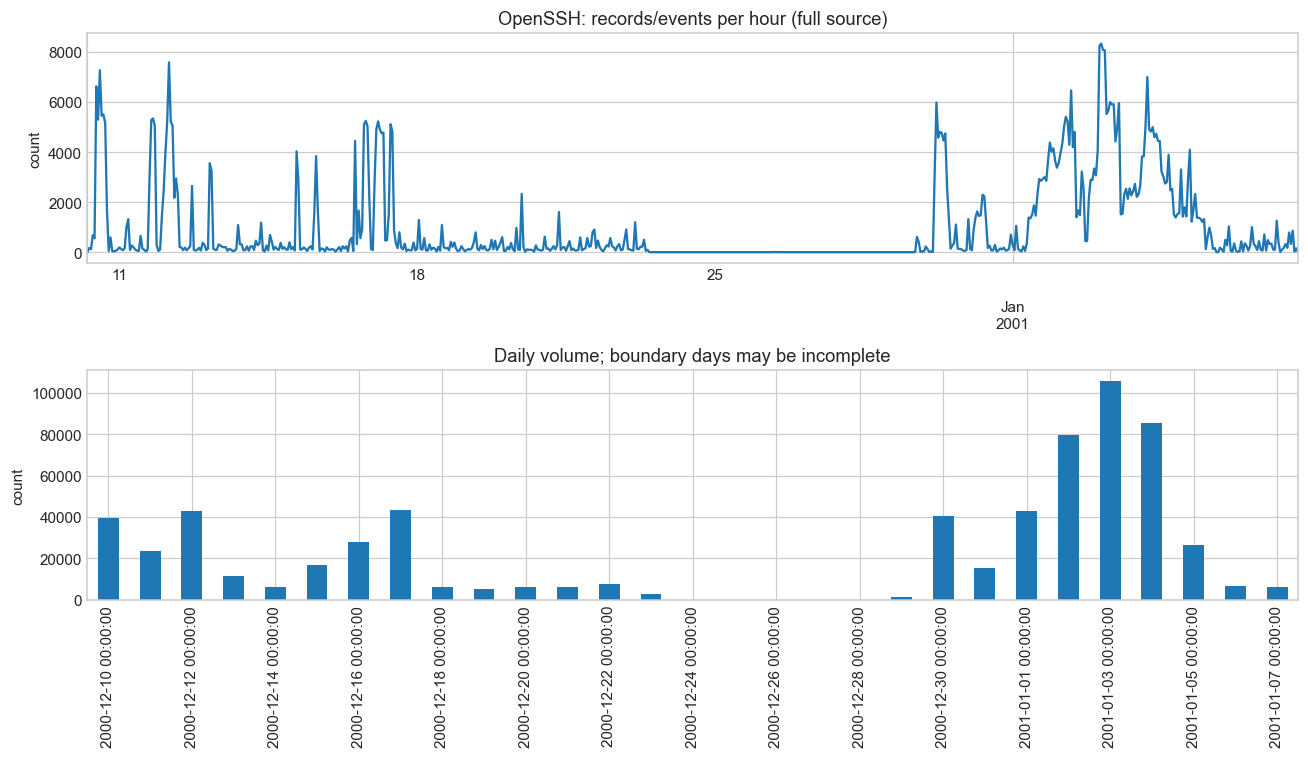

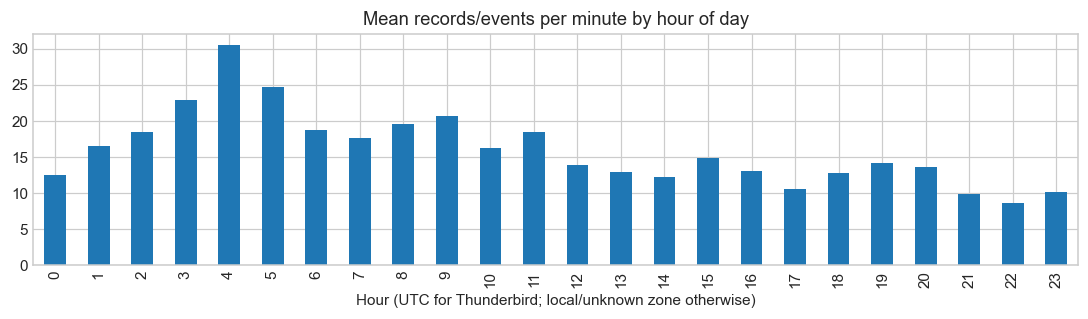

In [7]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7))
dense["count"].resample("1h").sum().plot(ax=axes[0], title=f"{NAME}: records/events per hour (full source)")
dense["count"].resample("1D").sum().plot.bar(ax=axes[1], title="Daily volume; boundary days may be incomplete")
axes[1].set_xticks(axes[1].get_xticks()[::max(1, len(dense.resample("1D").sum()) // 12)])
for ax in axes:
    ax.set_ylabel("count")
plt.tight_layout()
plt.show()
fig, ax = plt.subplots(figsize=(10, 3))
dense.groupby(dense.index.hour)["count"].mean().plot.bar(ax=ax, title="Mean records/events per minute by hour of day")
ax.set_xlabel("Hour (UTC for Thunderbird; local/unknown zone otherwise)")
plt.tight_layout()
plt.show()

In [8]:
for column in ["component", "host", "level"]:
    display(Markdown(f"**{column}: частоты и изменение долей ({SCOPE})**"))
    display(distribution(events, column).head(12))
    changes, tvd = drift(events, column)
    display({"total_variation_distance": tvd})
    display(changes.head(8))

**component: частоты и изменение долей (все физические строки и восстановленные события полного файла)**

,count,fraction
component,,
sshd,655147,1.0


{'total_variation_distance': 0.0}

period,first_half,second_half,delta
component,,,
sshd,1.0,1.0,0.0


**host: частоты и изменение долей (все физические строки и восстановленные события полного файла)**

,count,fraction
host,,
LabSZ,655147,1.0


... (2 outputs left out)

**level: частоты и изменение долей (все физические строки и восстановленные события полного файла)**

,count,fraction
level,,
<missing>,655147,1.0


{'total_variation_distance': 0.0}

period,first_half,second_half,delta
level,,,
<missing>,1.0,1.0,0.0


## 6. Сообщения

Длины измеряем в символах Unicode. Выброс — выше Q3 + 1,5×IQR, это статистическое правило, а не метка аномалии. Слова: латинские буквенные токены длиной от двух символов, lowercase, без stop-word фильтра. Биграммы не пересекают границы сообщений. Редкие токены и сообщения сохраняют параметры, поэтому их редкость ещё не означает новое поведение. Ссылки на компоненты ищем среди 20 наиболее активных имён; совпадение текста не устанавливает сетевую зависимость.

,message_characters
count,655147.000000
mean,75.380995
std,26.960336
min,31.000000
1%,37.000000
50%,62.000000
90%,113.000000
95%,114.000000
99%,139.000000
max,153.000000


{'IQR_cutoff': 170.5, 'outlier_events': 0}

,line_no,message_length,message
228389,228390,153,pam_unix(sshd:auth): authentication failure; logname= uid=0 euid=0 tty=ssh ruser= rhost=ipservice-092-211-201-236.092.211.pools.vodafone...
23112,23113,152,pam_unix(sshd:auth): authentication failure; logname= uid=0 euid=0 tty=ssh ruser= rhost=ec2-52-80-34-196.cn-north-1.compute.amazonaws.co...
27710,27711,152,pam_unix(sshd:auth): authentication failure; logname= uid=0 euid=0 tty=ssh ruser= rhost=ec2-52-80-34-196.cn-north-1.compute.amazonaws.co...
31925,31926,152,pam_unix(sshd:auth): authentication failure; logname= uid=0 euid=0 tty=ssh ruser= rhost=ec2-52-80-34-196.cn-north-1.compute.amazonaws.co...
215852,215853,151,reverse mapping checking getaddrinfo for 186-224-163-77.metroethernet.dynamic.fst.sp.faster.net.br [186.224.163.77] failed - POSSIBLE BR...


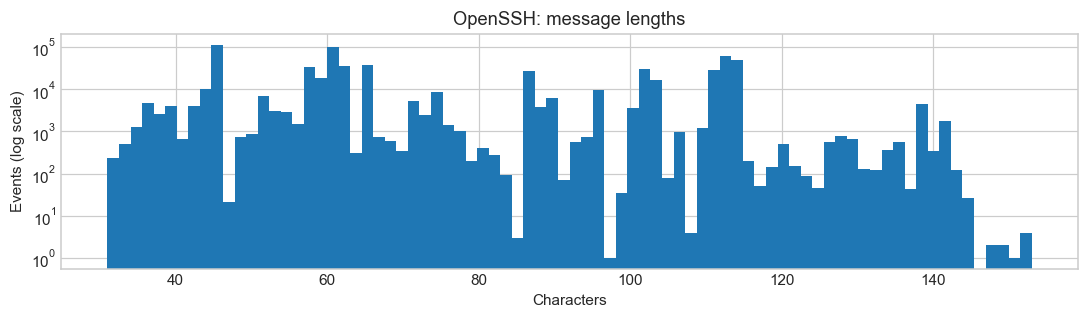

**words: самые частые и редкие**

,token,count
0,ssh,391597
1,root,390150
2,from,263312
3,for,254867
4,user,250621
5,authentication,231609
6,failed,217889
7,sshd,213316
8,port,198237
9,password,197769


,token,count
2069,ab,1
2070,abs,1
2071,ad,1
2072,aircel,1
2073,allband,1
2074,an,1
2075,apure,1
2076,arvixevps,1
2077,awasr,1
2078,awecsakira,1


**bigrams: самые частые и редкие**

,token,count
0,for root,213353
1,from port,198223
2,port ssh,198201
3,password for,197769
4,failed password,197587
5,euid tty,193375
6,logname uid,193375
7,ruser rhost,193375
8,ssh ruser,193375
9,tty ssh,193375


,token,count
4911,aaa preauth,1
4912,ab ru,1
4913,abc preauth,1
4914,abs static,1
4915,activemq preauth,1
4916,ad bb,1
4917,addr arpa,1
4918,addr btopenworld,1
4919,adminssh preauth,1
4920,adminstrator preauth,1


... (2 outputs left out)

,count
message,
PAM service(sshd) ignoring max retries; 6 > 3,37172
Disconnecting: Too many authentication failures for root [preauth],36569
pam_unix(sshd:auth): check pass; user unknown,19852
Connection closed by 183.63.110.206 [preauth],17340
pam_unix(sshd:auth): authentication failure; logname= uid=0 euid=0 tty=ssh ruser= rhost=183.63.110.206 user=root,17340
pam_unix(sshd:auth): authentication failure; logname= uid=0 euid=0 tty=ssh ruser= rhost=183.238.178.195 user=root,14519
Connection closed by 183.238.178.195 [preauth],14519
pam_unix(sshd:auth): authentication failure; logname= uid=0 euid=0 tty=ssh ruser= rhost=59.63.188.30 user=root,14384
PAM 5 more authentication failures; logname= uid=0 euid=0 tty=ssh ruser= rhost=59.63.188.30 user=root,14382


,count
singleton_message,
Failed password for root from 183.62.140.253 port 39917 ssh2,1
Failed password for root from 183.62.140.253 port 40258 ssh2,1
Failed password for root from 183.62.140.253 port 40900 ssh2,1
Failed password for root from 183.62.140.253 port 42172 ssh2,1
Failed password for root from 183.62.140.253 port 42570 ssh2,1
Failed password for root from 183.62.140.253 port 43244 ssh2,1
Failed password for root from 183.62.140.253 port 44843 ssh2,1
Failed password for root from 183.62.140.253 port 45253 ssh2,1
Failed password for root from 183.62.140.253 port 45566 ssh2,1


,count
message_seen_2_to_5,
Failed password for invalid user admin from 123.249.20.41 port 2956 ssh2,5
Failed password for invalid user admin from 185.222.209.151 port 55834 ssh2,5
Invalid user deluge from 221.164.9.48,5
Failed password for invalid user admin from 185.222.209.151 port 57522 ssh2,5
input_userauth_request: invalid user deluge [preauth],5
Failed password for invalid user admin from 181.214.87.4 port 50258 ssh2,5
Failed password for invalid user admin from 185.190.58.151 port 33863 ssh2,5
Failed password for invalid user admin from 181.214.87.4 port 33984 ssh2,5
Invalid user ftpuser from 103.217.152.20,5


,producer,mentioned_component,events


In [9]:
text_stats = message_statistics(events)
display(text_stats["lengths"].to_frame("message_characters"))
display({"IQR_cutoff": text_stats["outlier_cutoff_IQR"], "outlier_events": text_stats["outliers"]})
display(events.nlargest(5, "message_length")[["line_no", "message_length", "message"]])
fig, ax = plt.subplots(figsize=(10, 3))
ax.hist(events.message_length, bins=80, log=True)
ax.set(title=f"{NAME}: message lengths", xlabel="Characters", ylabel="Events (log scale)")
plt.tight_layout()
plt.show()
for kind in ["words", "bigrams"]:
    display(Markdown(f"**{kind}: самые частые и редкие**"))
    display(text_stats[kind].head(12))
    display(text_stats[kind].sort_values(["count", "token"]).head(12))
characters = text_stats["characters"].to_frame("characters")
characters["fraction"] = characters.characters / characters.characters.sum()
display(characters)
display(text_stats["frequency_bands"].to_frame("unique_message_count"))
display(text_stats["messages"].head(10).rename_axis("message").to_frame("count"))
display(text_stats["messages"].loc[lambda s: s.eq(1)].head(10).rename_axis("singleton_message").to_frame("count"))
display(text_stats["messages"].loc[lambda s: s.between(2, 5)].head(10).rename_axis("message_seen_2_to_5").to_frame("count"))
display(component_mentions(events))

## 7. Сущности и кандидаты в сессии

Регулярные выражения выделяют IPv4/IPv6, порты, UUID, пути, URL, кандидаты в хэши и устройства, явные session ID. Синтаксис IP проверяется через `ipaddress`, порты ограничены 0–65535. Даже корректная по форме последовательность может оказаться частью другого идентификатора; это не подтверждение сетевой роли сущности. Пути, хэши и устройства — **кандидаты**, а не подтверждённые типы: 32 hex-символа могут быть ID, `/10.0.0.1` — адресом, а не путём. Классы могут пересекаться; их суммы нельзя складывать как число сущностей. Ищем в сообщениях, без полей заголовка.

ZooKeeper: явный `session id 0x…`. OpenSSH: `(host, PID, сегмент активности с разрывом >30 минут)` — эвристика, PID переиспользуется и не равен ID соединения. Для Mac и Thunderbird универсальный session ID не заявляем.

In [10]:
entities, entity_examples = entity_counts(events)
display(entities)
for kind, examples in entity_examples.items():
    display(Markdown(f"**{kind}: примеры и число упоминаний**"))
    display(examples)
sessions = session_candidates(events, NAME)
display({"candidate_sessions": len(sessions)})
display(sessions.head(10))

,unique,mentions,events_with_entity
entity,,,
ipv4,1187,542851,542848
ipv6,1,3,3
port,53736,198235,198235
uuid,0,0,0
path,1,3,3
url,0,0,0
hash_candidate,0,0,0
device_candidate,0,0,0
session_id,0,0,0


**ipv4: примеры и число упоминаний**

,value,mentions
0,59.63.188.30,57539
1,183.63.110.206,52020
2,183.238.178.195,43557
3,183.192.189.131,35020
4,183.62.140.253,32953
5,139.219.191.138,32934
6,58.242.83.25,28767
7,183.129.154.138,26010
8,183.63.172.52,22518
9,218.65.30.30,20950


**ipv6: примеры и число упоминаний**

,value,mentions
0,::,3


**port: примеры и число упоминаний**

... (11 outputs left out)

**session_id: примеры и число упоминаний**

,value,mentions


{'candidate_sessions': 157119}

,events,first,last,duration_seconds
session,,,,
LabSZ:28096:1,19,2000-12-16 15:23:11,2000-12-16 15:23:25,14.0
LabSZ:4184:2,19,2001-01-01 06:29:04,2001-01-01 06:29:18,14.0
LabSZ:25887:5,19,2001-01-06 21:32:26,2001-01-06 21:32:42,16.0
LabSZ:19500:4,19,2001-01-05 14:54:31,2001-01-05 14:54:42,11.0
LabSZ:7489:1,19,2000-12-13 23:35:24,2000-12-13 23:35:40,16.0
LabSZ:7505:2,19,2001-01-04 21:57:07,2001-01-04 21:57:19,12.0
LabSZ:8040:3,19,2000-12-18 14:59:48,2000-12-18 15:00:02,14.0
LabSZ:20056:3,19,2001-01-04 06:04:39,2001-01-04 06:04:53,14.0
LabSZ:2298:2,19,2000-12-31 15:02:05,2000-12-31 15:02:19,14.0


## 8. Шаблоны событий

Используем [Drain3](https://github.com/logpai/Drain3), `depth=4`, `sim_th=0.4`, с масками UUID/IP/HEX/NUM. Обучаем на текстах сообщений в порядке файла, без времён и labels. Для каждого cluster ID показываем **финальный** шаблон, потому что при обучении он обобщается. Это исследовательская кластеризация, не оценка точности парсинга. Время первого/последнего наблюдения и число дней не доказывают рождение/исчезновение события вне периода наблюдения. Для Thunderbird это особенно существенно: редкий шаблон мог не попасть в выборку.

{'templates': 45, 'singleton_templates': 5}

,count,template,first,last,observed_days
template_id,,,,,
10,140768,Failed password for <*> from <IP> port <NUM> ssh2,2000-12-10 07:13:43,2001-01-07 17:07:13,24
9,140701,pam_unix(sshd:auth): authentication failure; logname= uid=<NUM> euid=<NUM> tty=ssh ruser= <*> <*>,2000-12-10 07:13:31,2001-01-07 17:07:11,24
7,68958,Connection closed by <IP> [preauth],2000-12-10 06:55:48,2001-01-07 16:56:34,24
8,46642,Received disconnect from <IP>: <NUM>: <*> <*> <*>,2000-12-10 07:07:45,2001-01-07 17:07:14,24
14,37963,PAM service(sshd) ignoring max retries; <NUM> > <NUM>,2000-12-10 07:13:56,2001-01-07 16:21:30,24
12,37298,Disconnecting: Too many authentication failures for <*> [preauth],2000-12-10 07:13:56,2001-01-07 14:16:41,24
13,37029,PAM <NUM> more authentication <*> logname= uid=<NUM> euid=<NUM> tty=ssh ruser= <*> <*>,2000-12-10 07:13:56,2001-01-07 16:21:30,24
11,36967,message repeated <NUM> times: [ Failed password for <*> from <IP> port <NUM> ssh2],2000-12-10 07:13:56,2001-01-07 16:21:28,24
6,20271,Failed <*> for invalid user <*> from <IP> port <NUM> ssh2,2000-12-10 06:55:48,2001-01-07 16:21:19,24


,count,template,first,last,observed_days
template_id,,,,,
26,1,Bad packet length <NUM>. [preauth],2000-12-11 00:55:49,2000-12-11 00:55:49,1
41,1,Corrupted MAC on input. [preauth],2000-12-16 23:45:43,2000-12-16 23:45:43,1
27,1,Disconnecting: Packet corrupt [preauth],2000-12-11 00:55:49,2000-12-11 00:55:49,1
37,1,Received disconnect from <IP>: <NUM>:,2000-12-14 05:41:05,2000-12-14 05:41:05,1
45,1,syslogin_perform_logout: logout() returned an error,2001-01-06 12:52:23,2001-01-06 12:52:23,1
25,2,error: Received disconnect from <IP>: <NUM>: User request [preauth],2000-12-10 17:53:24,2000-12-14 12:55:05,2
39,3,error: Received disconnect from <IP>: <NUM>: com.jcraft.jsch.JSchException: timeout in waiting for rekeying process. [preauth],2000-12-14 21:19:12,2001-01-05 09:47:34,3
23,3,fatal: Write failed: Connection reset by peer [preauth],2000-12-10 11:03:53,2000-12-30 10:59:10,2
43,6,Server listening on <*> port <NUM>.,2000-12-26 10:55:32,2000-12-26 10:55:32,1


,count,template,first,last,observed_days
template_id,,,,,
4,19852,pam_unix(sshd:auth): check pass; user unknown,2000-12-10 06:55:46,2001-01-07 16:21:17,24
5,14356,pam_unix(sshd:auth): authentication failure; logname= uid=<NUM> euid=<NUM> tty=ssh ruser= <*>,2000-12-10 06:55:46,2001-01-07 16:21:17,24
3,14581,input_userauth_request: invalid user <*> [preauth],2000-12-10 06:55:46,2001-01-07 16:21:17,24
2,14581,Invalid user <*> from <IP>,2000-12-10 06:55:46,2001-01-07 16:21:17,24
1,18909,reverse mapping checking getaddrinfo for <*> [<IP>] failed - POSSIBLE BREAK-IN ATTEMPT!,2000-12-10 06:55:46,2001-01-07 15:26:44,24
7,68958,Connection closed by <IP> [preauth],2000-12-10 06:55:48,2001-01-07 16:56:34,24
6,20271,Failed <*> for invalid user <*> from <IP> port <NUM> ssh2,2000-12-10 06:55:48,2001-01-07 16:21:19,24
8,46642,Received disconnect from <IP>: <NUM>: <*> <*> <*>,2000-12-10 07:07:45,2001-01-07 17:07:14,24
9,140701,pam_unix(sshd:auth): authentication failure; logname= uid=<NUM> euid=<NUM> tty=ssh ruser= <*> <*>,2000-12-10 07:13:31,2001-01-07 17:07:11,24


,count,template,first,last,observed_days,days_since_last
template_id,,,,,,
26,1,Bad packet length <NUM>. [preauth],2000-12-11 00:55:49,2000-12-11 00:55:49,1,27.684861
27,1,Disconnecting: Packet corrupt [preauth],2000-12-11 00:55:49,2000-12-11 00:55:49,1,27.684861
37,1,Received disconnect from <IP>: <NUM>:,2000-12-14 05:41:05,2000-12-14 05:41:05,1,24.486759
25,2,error: Received disconnect from <IP>: <NUM>: User request [preauth],2000-12-10 17:53:24,2000-12-14 12:55:05,2,24.185370
41,1,Corrupted MAC on input. [preauth],2000-12-16 23:45:43,2000-12-16 23:45:43,1,21.733542
30,6,fatal: no hostkey alg [preauth],2000-12-11 19:03:21,2000-12-20 17:36:20,3,17.990058
42,60,Received disconnect from <IP>: <NUM>: disconnect [preauth],2000-12-19 15:22:04,2000-12-22 18:45:16,3,15.942187
43,6,Server listening on <*> port <NUM>.,2000-12-26 10:55:32,2000-12-26 10:55:32,1,12.268391
23,3,fatal: Write failed: Connection reset by peer [preauth],2000-12-10 11:03:53,2000-12-30 10:59:10,2,8.265868


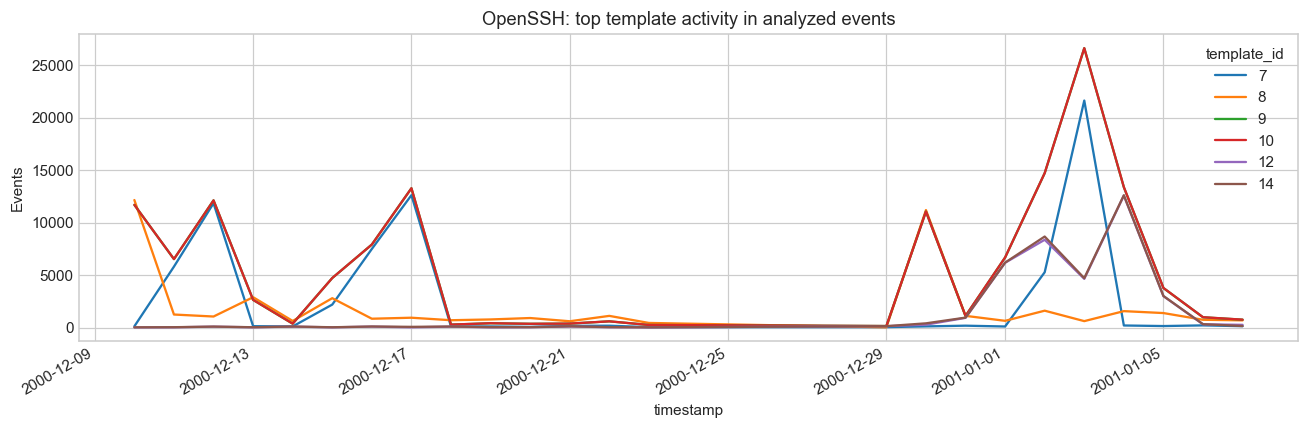

In [11]:
events, templates = mine_templates(events)
assert templates["count"].sum() == len(events)
display({"templates": len(templates), "singleton_templates": int(templates["count"].eq(1).sum())})
display(templates.head(12))
display(templates.sort_values(["count", "template"]).head(12))
display(templates.sort_values("first").head(10))
observation_end = events.timestamp.max()
template_inactivity = templates.assign(days_since_last=(observation_end - templates["last"]).dt.total_seconds() / 86400)
display(template_inactivity.sort_values("days_since_last", ascending=False).head(10))
top_ids = templates.head(6).index
activity = events.loc[events.template_id.isin(top_ids)].groupby([pd.Grouper(key="timestamp", freq="1D"), "template_id"]).size().unstack(fill_value=0)
activity.plot(figsize=(12, 4), title=f"{NAME}: top template activity in analyzed events")
plt.ylabel("Events")
plt.tight_layout()
plt.show()

## 9. Разметка и аномалии

Официальной разметки аномалий нет. Поэтому долю аномалий, длительность размеченных инцидентов, label-exclusive шаблоны и десять размеченных аномалий оценить нельзя. INFO/WARN/ERROR, `Failed password`, выбросы объёма и редкие шаблоны не подменяют ground truth. Ниже читаем десять **подозрительных по тексту примеров**, чтобы предложить будущие правила разметки; это не подтверждённые инциденты.

In [12]:
assert events.is_anomaly.isna().all()
candidates = events.loc[events.message.str.contains(r"error|fail|warn|exception|invalid|broken|timeout", case=False, regex=True)]
with pd.option_context("display.max_colwidth", None):
    display(candidates.drop_duplicates("message").head(10)[["line_no", "timestamp", "component", "message"]])
display({"text_rule_candidate_events": len(candidates), "ground_truth_anomaly_count": "unknown"})

,line_no,timestamp,component,message
0,1,2000-12-10 06:55:46,sshd,reverse mapping checking getaddrinfo for ns.marryaldkfaczcz.com [173.234.31.186] failed - POSSIBLE BREAK-IN ATTEMPT!
1,2,2000-12-10 06:55:46,sshd,Invalid user webmaster from 173.234.31.186
2,3,2000-12-10 06:55:46,sshd,input_userauth_request: invalid user webmaster [preauth]
4,5,2000-12-10 06:55:46,sshd,pam_unix(sshd:auth): authentication failure; logname= uid=0 euid=0 tty=ssh ruser= rhost=173.234.31.186
5,6,2000-12-10 06:55:48,sshd,Failed password for invalid user webmaster from 173.234.31.186 port 38926 ssh2
8,9,2000-12-10 07:07:38,sshd,Invalid user test9 from 52.80.34.196
9,10,2000-12-10 07:07:38,sshd,input_userauth_request: invalid user test9 [preauth]
11,12,2000-12-10 07:07:38,sshd,pam_unix(sshd:auth): authentication failure; logname= uid=0 euid=0 tty=ssh ruser= rhost=ec2-52-80-34-196.cn-north-1.compute.amazonaws.com.cn
12,13,2000-12-10 07:07:45,sshd,Failed password for invalid user test9 from 52.80.34.196 port 36060 ssh2
19,20,2000-12-10 07:08:30,sshd,Failed password for invalid user webmaster from 173.234.31.186 port 39257 ssh2


{'text_rule_candidate_events': 478871, 'ground_truth_anomaly_count': 'unknown'}

## 10. Временные окна

Сравниваем фиксированные непересекающиеся окна 1, 5, 15, 60 минут и сутки. Сетка покрывает весь наблюдаемый период, нулевые окна сохраняются. Крайние окна частичны. `above_p99` — разведочный индикатор концентрации; p99 не является порогом доказанной аномалии. Дисперсия/среднее описывает неравномерность нагрузки, но без стационарности не служит тестом на аномалии.

Считаем восстановленные события с валидным временем. Для Mac скрытые syslog-повторы не разворачиваем, поэтому это интенсивность опубликованных событий, не всех событий системы.

,windows,empty,empty_fraction,mean,median,p99,max,above_p99,variance_over_mean
window_minutes,,,,,,,,,
1,40948,27462,0.670655,15.999487,0.0,133.00,341,396,62.476022
5,8190,3813,0.465568,79.993529,2.0,636.00,1267,81,288.528814
15,2731,749,0.274259,239.892713,19.0,1829.80,2816,28,809.867048
60,684,148,0.216374,957.817251,140.5,6686.07,8331,7,2888.955305
1440,29,4,0.137931,22591.275862,7644.0,99919.64,105628,1,34396.843629


,count,alerts
2000-12-12 04:29:00,341,NaN
2000-12-12 04:28:00,328,NaN
2000-12-12 04:27:00,291,NaN
2000-12-12 04:34:00,249,NaN
2000-12-12 04:40:00,247,NaN
2000-12-12 04:30:00,246,NaN
2000-12-12 04:33:00,244,NaN
2001-01-03 12:22:00,241,NaN
2000-12-12 04:39:00,231,NaN
2001-01-03 12:23:00,230,NaN


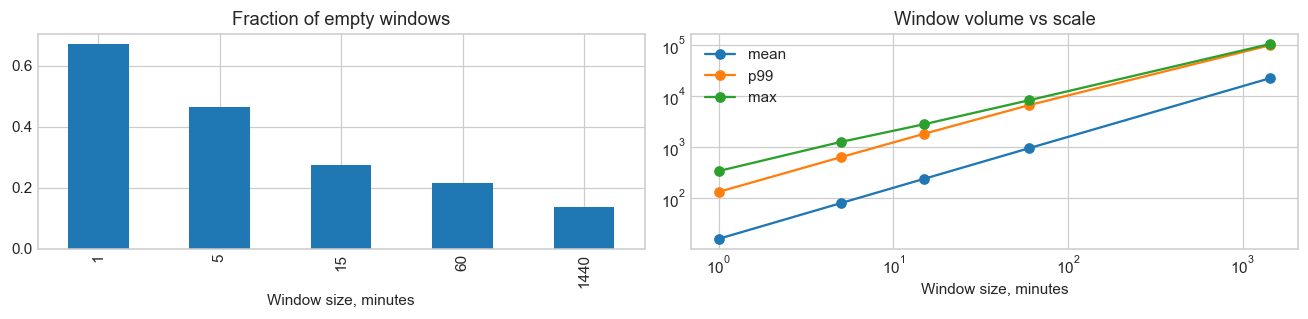

In [13]:
windows = window_summary(minutes)
display(windows)
display(dense.nlargest(10, "count"))
fig, axes = plt.subplots(1, 2, figsize=(12, 3))
windows.empty_fraction.plot.bar(ax=axes[0], title="Fraction of empty windows")
windows[["mean", "p99", "max"]].plot(ax=axes[1], marker="o", logy=True, logx=True, title="Window volume vs scale")
axes[0].set_xlabel("Window size, minutes")
axes[1].set_xlabel("Window size, minutes")
plt.tight_layout()
plt.show()

## 11. Проверяемый дайджест и открытые вопросы

Следующая ячейка собирает ключевые числа из текущего запуска. В финальной Markdown-ячейке — их интерпретация и ограничения.

In [14]:
digest = {
    "dataset": NAME,
    "physical_lines_full": int(source["physical_lines"]),
    "analyzed_events": len(events),
    "parse_fraction_physical": float(physical.parse_ok.mean()),
    "duplicates_in_analyzed_physical": int(physical.raw.duplicated().sum()),
    "multiline_events": int(events.physical_line_count.gt(1).sum()),
    "start": str(dense.index.min()), "end": str(dense.index.max()),
    "templates": len(templates), "singleton_templates": int(templates["count"].eq(1).sum()),
    "message_length_median": float(events.message_length.median()),
    "empty_minutes_fraction": float(windows.loc[1, "empty_fraction"]),
    "busiest_minute": str(dense["count"].idxmax()),
    "busiest_minute_count": int(dense["count"].max()),
    "top_component": str(events.component.value_counts().index[0]),
    "top_template": str(templates.iloc[0].template),
    "top_template_count": int(templates.iloc[0]["count"]),
    "entity_unique": {k: int(v) for k, v in entities["unique"].items()},
    "session_candidates": len(sessions),
    "unparsed_header_lines": int((physical.header_start & ~physical.parse_ok).sum()),
}

display(JSON(digest))

<IPython.core.display.JSON object>

### Выводы по OpenSSH

- Полный источник: **655,147 физических строк**. Анализ текстов: **655,147 событий**.
- Медиана длины сообщения — **62 символов**. Drain3 выделил **45 шаблонов**, из них **5** встречаются один раз.
- На полной временной сетке **67.07% пустых минут**. Максимум — **341 событий/минуту**, 2000-12-12 04:29:00. Крайние окна частичны.

Поток целиком продуцирует `sshd`, явного severity нет. Самый частый Drain3-шаблон — `Failed password for <*> from <IP> port <NUM> ssh2`: 140 768 строк. Десять подозрительных примеров показывают неуспешную аутентификацию, неизвестных пользователей и предупреждения reverse DNS. Эти сообщения согласуются с автоматическими попытками входа, но сами по себе не подтверждают успешный взлом или ground truth аномалии.

Найдено 1 187 IPv4-адресов в сообщениях и 157 119 кандидатов в сессии по `(host, PID, 30-минутный разрыв)`. У PID возможны повторное использование и неоднозначные границы, поэтому это начальная сегментация для проверки, а не достоверное число SSH-соединений. Для следующего шага полезны частоты ошибок аутентификации по IP/пользователю и последовательности событий внутри кандидата в сессию.

Фактически прочитано на одну строку больше каталога: последняя строка корректно разбирается, но не заканчивается LF. Год 2000/2001 условный, часовой пояс неизвестен. Дни недели по этому индексу анализировать нельзя.

**Открытые вопросы:** какие IP принадлежат легитимным пользователям и сканерам; какой реальный год/пояс; как связать PID с соединением и успешной аутентификацией; где взять независимую разметку атак? Пустые интервалы без внешних метрик не подтверждают недоступность сервера.

**Воспроизводимость:** полный архив Zenodo с закреплённым MD5, контроль SHA-256, фиксированный seed, явные правила парсинга, версии библиотек в начале. Подсчёты соответствуют параметрам этого выполненного ноутбука. Все 11 пунктов чеклиста рассмотрены; ограничения разметки и неизвестные поля указаны явно.